In [122]:
import pandas as pd
import polars as pl
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,roc_curve, auc,mean_squared_error,recall_score,
precision_recall_curve,log_loss,roc_auc_score,average_precision_score,f1_score)
from sklearn.model_selection import train_test_split,RepeatedKFold,cross_val_score,TimeSeriesSplit,GridSearchCV
from tqdm import tqdm
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.calibration import calibration_curve
import xgboost as xgb
import os
from pathlib import Path

In [123]:
PATH = "../data/processed/statcast_2022.parquet"
data = pl.read_parquet(PATH)

In [124]:
# data = pd.DataFrame() 
# years = ["2022","2023","2024","2025"]

# for y in years:
#     PATH = f"../data/processed/statcast_{y}.parquet"
#     data = pd.concat([data, pd.read_parquet(PATH)])
# data = pl.from_pandas(data)

In [125]:
data

pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,spin_dir,spin_rate_deprecated,break_angle_deprecated,break_length_deprecated,zone,des,game_type,stand,p_throws,home_team,away_team,type,hit_location,bb_type,balls,strikes,game_year,pfx_x,pfx_z,plate_x,plate_z,on_3b,on_2b,on_1b,outs_when_up,inning,inning_topbot,…,post_fld_score,if_fielding_alignment,of_fielding_alignment,spin_axis,delta_home_win_exp,delta_run_exp,bat_speed,swing_length,miss_distance,estimated_slg_using_speedangle,delta_pitcher_run_exp,hyper_speed,home_score_diff,bat_score_diff,home_win_exp,bat_win_exp,age_pit_legacy,age_bat_legacy,age_pit,age_bat,n_thruorder_pitcher,n_priorpa_thisgame_player_at_bat,pitcher_days_since_prev_game,batter_days_since_prev_game,pitcher_days_until_next_game,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches,hp_official_name,hp_official_id
str,datetime[ns],f64,f64,f64,str,i64,i64,str,str,i64,i64,i64,i64,i64,str,str,str,str,str,str,str,i64,str,i64,i64,i64,f64,f64,f64,f64,i64,i64,i64,i64,i64,str,…,i64,str,str,i64,f64,f64,i64,i64,i64,f64,f64,f64,i64,i64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,i64,i64,i64,i64,i64,str,i64
"""FF""",2022-04-03 00:00:00,95.2,-0.93,5.61,"""Duarte, Daniel""",647378,650960,"""field_out""","""hit_into_play""",null,null,null,null,7,"""Andy Yerzy grounds out, first …","""S""","""L""","""R""","""AZ""","""CIN""","""X""",3,"""ground_ball""",3,2,2022,-0.82,1.04,-0.4072,1.862515,null,677942,623323,2,9,"""Bot""",…,15,"""Infield shift""","""Standard""",212,-0.001,-0.306,null,null,null,null,0.306,90.9,-11,-11,0.001,0.001,25,23,26,24,1,0,null,null,null,null,1.47,0.82,-0.82,null,null,null,null,null,null,"""Jim Reynolds""",427424
"""CH""",2022-04-03 00:00:00,90.5,-1.38,5.29,"""Duarte, Daniel""",647378,650960,null,"""blocked_ball""",null,null,null,null,14,null,"""S""","""L""","""R""","""AZ""","""CIN""","""B""",null,null,2,2,2022,-1.29,0.63,0.006077,0.279364,null,677942,623323,2,9,"""Bot""",…,15,"""Infield shift""","""Standard""",238,0.0,0.072,null,null,null,null,-0.072,null,-11,-11,0.001,0.001,25,23,26,24,1,0,null,null,null,null,2.15,1.29,-1.29,null,null,null,null,null,null,"""Jim Reynolds""",427424
"""FF""",2022-04-03 00:00:00,92.0,-0.92,5.62,"""Duarte, Daniel""",647378,650960,null,"""foul""",null,null,null,null,2,null,"""S""","""L""","""R""","""AZ""","""CIN""","""S""",null,null,2,1,2022,-0.86,1.33,-0.082342,3.038304,null,677942,623323,2,9,"""Bot""",…,15,"""Infield shift""","""Standard""",210,0.0,-0.062,null,null,null,null,0.062,88.0,-11,-11,0.001,0.001,25,23,26,24,1,0,null,null,null,null,1.35,0.86,-0.86,null,null,null,null,null,null,"""Jim Reynolds""",427424
"""CH""",2022-04-03 00:00:00,89.1,-1.3,5.34,"""Duarte, Daniel""",647378,650960,null,"""blocked_ball""",null,null,null,null,14,null,"""S""","""L""","""R""","""AZ""","""CIN""","""B""",null,null,1,1,2022,-1.28,0.32,0.789404,0.525492,null,677942,623323,2,9,"""Bot""",…,15,"""Infield shift""","""Standard""",231,0.0,0.035,null,null,null,null,-0.035,null,-11,-11,0.001,0.001,25,23,26,24,1,0,null,null,null,null,2.55,1.28,-1.28,null,null,null,null,null,null,"""Jim Reynolds""",427424
"""FF""",2022-04-03 00:00:00,94.5,-0.94,5.51,"""Duarte, Daniel""",647378,650960,null,"""called_strike""",null,null,null,null,9,null,"""S""","""L""","""R""","""AZ""","""CIN""","""S""",null,null,1,0,2022,-0.6,1.22,0.652451,1.724418,null,677942,623323,2,9,"""Bot""",…,15,"""Infield shift""","""Standard""",213,0.0,-0.035,null,null,null,null,0.035,null,-11,-11,0.001,0.001,25,23,26,24,1,0,null,null,null,null,1.32,0.6,-0.6,null,null,null,null,null,null,"""Jim Reynolds""",427424
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FC""",2022-10-07 00:00:00,87.2

In [126]:
#missed balls
data = (
    data
    .with_columns (
        (
            (
                (pl.col("plate_x") < -0.7083)
                | (pl.col("plate_x") > 0.7083)

                | (pl.col("plate_z") < pl.col("sz_bot"))
                | (pl.col("plate_z") > pl.col("sz_top"))
            )
           & (pl.col("description")=="called_strike")
        )
        
         .cast(pl.Int8)
        .alias("is_missed_ball")
    )
)

In [127]:
#missed strikes
data = (
    data
    .with_columns (
        (
            (
                (pl.col("plate_x") >= -0.7083)
                & (pl.col("plate_x") <= 0.7083)

                & (pl.col("plate_z") >= pl.col("sz_bot"))
                & (pl.col("plate_z") <= pl.col("sz_top"))
            )
           & (pl.col("description")=="ball")
        )
        
         .cast(pl.Int8)
        .alias("is_missed_strike")
    )
)

In [128]:
data = data.filter(pl.col("description").is_in(["called_strike", "ball"]) & 
                (pl.col("plate_x").is_not_null()) &
                (pl.col("sz_top").is_not_null())
                )
data = data.with_columns((pl.col("is_missed_ball") | pl.col("is_missed_strike")).alias("wrong_call"))
data = data.to_pandas()

In [129]:
pitch_mapping = {
    "FF": "Fastball", "SI": "Fastball", "FC": "Fastball", "FA": "Fastball",
    "SL": "Slider",   "ST": "Slider",   "SV": "Slider",
    "CU": "Curveball","KC": "Curveball","CS": "Curveball",
    "CH": "Changeup", "FS": "Changeup", "FO": "Changeup", "SC": "Changeup",
    "EP": "Junk",     "KN": "Junk"
}

data["pitch_cat"] = data["pitch_type"].map(pitch_mapping)
data["count"] = data["balls"].astype(str) + "-" + data["strikes"].astype(str)
data["same_hand"] = (data["stand"] == data["p_throws"]).astype(int)
data["wrong_call"] = data["is_missed_ball"] | data["is_missed_strike"]
data['call'] = data['description']
data["month"] = pd.to_datetime(data["game_date"]).dt.month
data["zone"] = data["zone"].astype(int).astype(str) 
data["pitcher"] = data["pitcher"].astype(int).astype(str) 
data["batter"] = data["batter"].astype(int).astype(str) 
data["called_strike"] = (data["description"] == "called_strike").astype(int)

In [130]:
feature_cols = [
    "release_speed",
    "release_spin_rate",
    "pitch_cat",
    "zone",
    "balls",
    "strikes",
    "inning",
    "outs_when_up",
    "inning_topbot",
    "stand",
    "p_throws",
    "n_thruorder_pitcher",
    "sz_top",
    "sz_bot",
    "called_strike",
    "pitcher",
    "batter",
    "pitch_number",
    "pitcher_days_since_prev_game"
]

In [131]:
response_col = [
    #"is_missed_ball",
    #"is_missed_strike",
    "wrong_call"
][0]

In [132]:
# 1) sort by date so TimeSeriesSplit folds are real time blocks
data = data.sort_values("game_date").reset_index(drop=True)

# 2) cast categorical columns BEFORE building X
cat_cols = [
"pitch_cat",
"zone" ,
 "inning_topbot", 
 "stand", 
 "p_throws", 
 "pitcher", 
 "batter"
 ]
for c in cat_cols:
    data[c] = data[c].astype("category")
num_cols = [c for c in feature_cols if c not in cat_cols]

# 3) build X / y AFTER the cast
X = data[feature_cols]
y = data[response_col]

split = int(len(X) * 0.8)
train_features, test_features = X.iloc[:split], X.iloc[split:]
train_response, test_response = y.iloc[:split], y.iloc[split:]

# 4) sanity checks
bad = {c: str(train_features[c].dtype) for c in cat_cols if train_features[c].dtype.name != "category"}
assert not bad, f"not category: {bad}"
print(f"train rows={len(train_features):>7} pos={int(train_response.sum()):>6} rate={train_response.mean():.4f}")
print(f"test  rows={len(test_features):>7} pos={int(test_response.sum()):>6} rate={test_response.mean():.4f}")

for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=5).split(train_features)):
    print(f"fold {i}: test pos = {int(train_response.iloc[te].sum())}")

cv = TimeSeriesSplit(n_splits=5)

xgb_model = xgb.XGBClassifier(
    random_state=6740,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    enable_categorical=True,
    n_jobs=1,
    device = "cuda",
    scale_pos_weight=20
)

pipe = Pipeline(steps=[("xgb", xgb_model)])

param_grid = {
    "xgb__n_estimators":    [500, 550],
    "xgb__learning_rate":   [0.1,0.15],
    "xgb__max_depth":       [3, 4],
    "xgb__gamma":           [1 ,2],
}

search = GridSearchCV(
    pipe, param_grid,
    cv=cv,
    scoring="average_precision",
    n_jobs=1,
    verbose=2,
    error_score="raise",
)
search.fit(train_features, train_response)

print("Best params:", search.best_params_)
print("Best CV PR-AUC:", search.best_score_)

train rows= 297003 pos= 33057 rate=0.1113
test  rows=  74251 pos=  8025 rate=0.1081
fold 0: test pos = 5436
fold 1: test pos = 5328
fold 2: test pos = 5513
fold 3: test pos = 5521
fold 4: test pos = 5461
Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END xgb__gamma=1, xgb__learning_rate=0.1, xgb__max_depth=3, xgb__n_estimators=500; total time=   1.6s
[CV] END xgb__gamma=1, xgb__learning_rate=0.1, xgb__max_depth=3, xgb__n_estimators=500; total time=   1.5s
[CV] END xgb__gamma=1, xgb__learning_rate=0.1, xgb__max_depth=3, xgb__n_estimators=500; total time=   1.6s
[CV] END xgb__gamma=1, xgb__learning_rate=0.1, xgb__max_depth=3, xgb__n_estimators=500; total time=   1.7s
[CV] END xgb__gamma=1, xgb__learning_rate=0.1, xgb__max_depth=3, xgb__n_estimators=500; total time=   1.8s
[CV] END xgb__gamma=1, xgb__learning_rate=0.1, xgb__max_depth=3, xgb__n_estimators=550; total time=   1.5s
[CV] END xgb__gamma=1, xgb__learning_rate=0.1, xgb__max_depth=3, xgb__n_estimators=550; total

In [133]:
print("Best params:", search.best_params_)

Best params: {'xgb__gamma': 2, 'xgb__learning_rate': 0.1, 'xgb__max_depth': 3, 'xgb__n_estimators': 500}


In [134]:
import pandas as pd
import numpy as np
from sklearn.base import clone

# Reference score from the fitted GridSearchCV
baseline_score = float(search.best_score_)
target_score = baseline_score * 0.95

results = pd.DataFrame(search.cv_results_)
results["distance_from_target"] = (
    results["mean_test_score"] - target_score
).abs()

# Prefer a tested model that is below the target score
degraded_candidates = results[
    results["mean_test_score"] <= target_score
]

if not degraded_candidates.empty:
    row = degraded_candidates.loc[
        degraded_candidates["distance_from_target"].idxmin()
    ]
else:
    # No exact target exists; select the closest weaker result
    weaker_candidates = results[
        results["mean_test_score"] < baseline_score
    ]

    if weaker_candidates.empty:
        raise RuntimeError(
            "The parameter grid contains no model weaker than the baseline."
        )

    row = weaker_candidates.loc[
        weaker_candidates["distance_from_target"].idxmin()
    ]

degraded_params = row["params"]
degraded_score = float(row["mean_test_score"])

# This creates the selected model; it does not require fitting it again
degraded_model = clone(search.estimator)
degraded_model.set_params(**degraded_params)

actual_relative_change = (
    (degraded_score - baseline_score) / baseline_score
) * 100

print(f"Baseline CV score: {baseline_score:.4f}")
print(f"Target CV score:   {target_score:.4f}")
print(f"Degraded CV score: {degraded_score:.4f}")
print(f"Relative change:   {actual_relative_change:.2f}%")
print("Degraded params:", degraded_params)

Baseline CV score: 0.7104
Target CV score:   0.6749
Degraded CV score: 0.7045
Relative change:   -0.83%
Degraded params: {'xgb__gamma': 2, 'xgb__learning_rate': 0.15, 'xgb__max_depth': 4, 'xgb__n_estimators': 550}


In [135]:
final_model = clone(pipe).set_params(**search.best_params_)
final_model.fit(train_features, train_response)

xgb_train_probs = final_model.predict_proba(train_features)[:, 1]
xgb_test_probs  = final_model.predict_proba(test_features)[:, 1]

pr, rc, th = precision_recall_curve(train_response, xgb_train_probs)
thr = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]
xgb_train_preds = (xgb_train_probs >= thr).astype(int)
xgb_test_preds  = (xgb_test_probs  >= thr).astype(int)

for name, yt, pp, pred in [("Train", train_response, xgb_train_probs, xgb_train_preds),
                           ("Test",  test_response,  xgb_test_probs,  xgb_test_preds)]:
    print(f"XGB {name}: LogLoss {log_loss(yt, pp):.4f} | ROC-AUC {roc_auc_score(yt, pp):.4f} | "
          f"PR-AUC {average_precision_score(yt, pp):.4f} | F1 {f1_score(yt, pred):.4f} | base rate {yt.mean():.3f}")

results = pd.DataFrame({
    'actual':     pd.concat([train_response, test_response]).values,
    'pred_prob':  np.concatenate([xgb_train_probs, xgb_test_probs]),
    'pred_label': np.concatenate([xgb_train_preds, xgb_test_preds]),
    'split':      ['train'] * len(train_response) + ['test'] * len(test_response)})

XGB Train: LogLoss 0.2997 | ROC-AUC 0.9820 | PR-AUC 0.8817 | F1 0.7696 | base rate 0.111
XGB Test: LogLoss 0.3418 | ROC-AUC 0.9362 | PR-AUC 0.7143 | F1 0.5814 | base rate 0.108


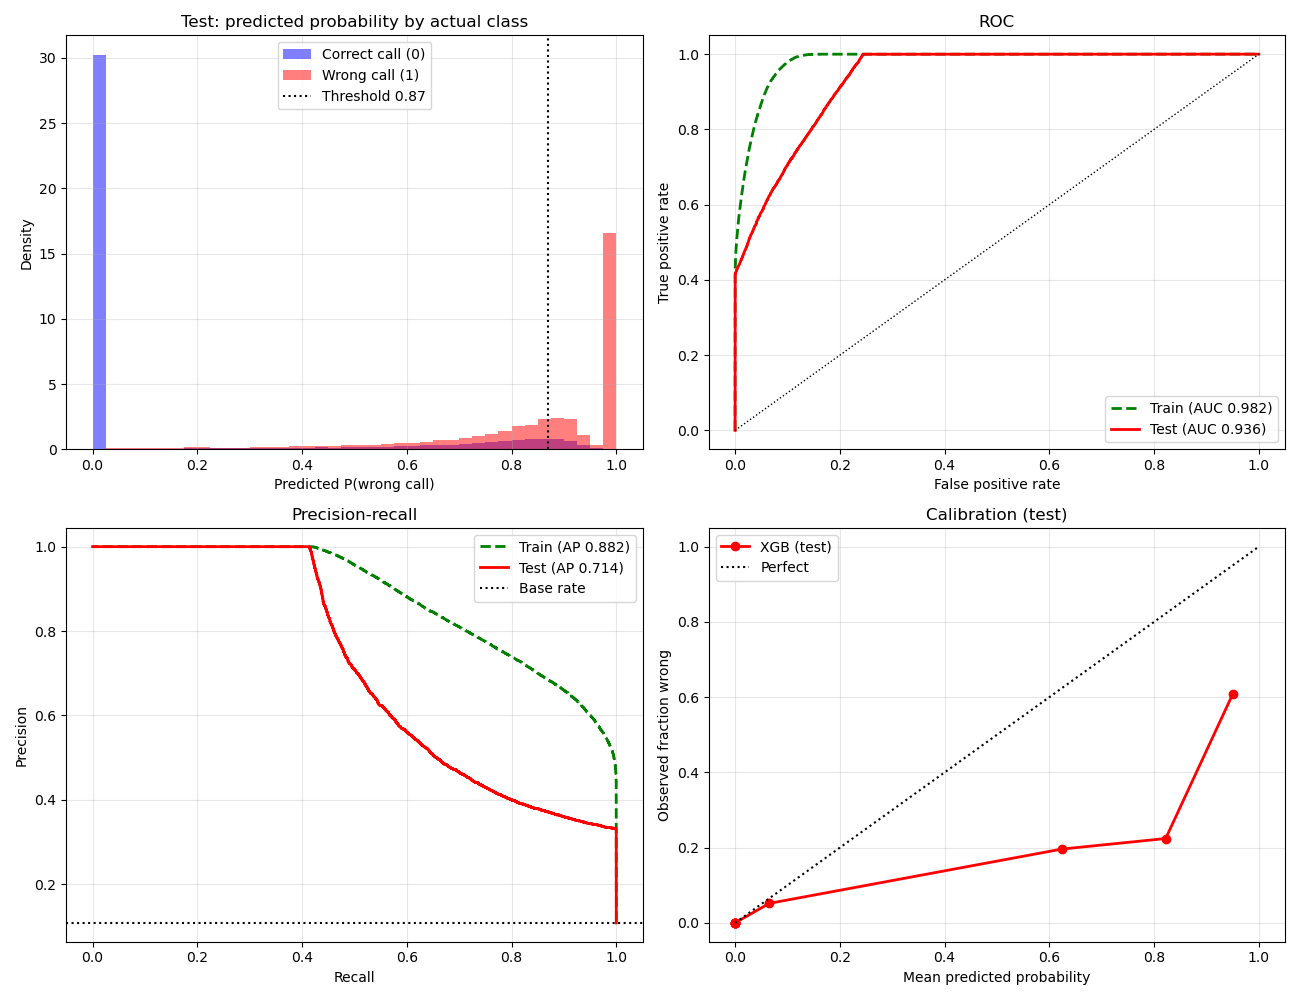

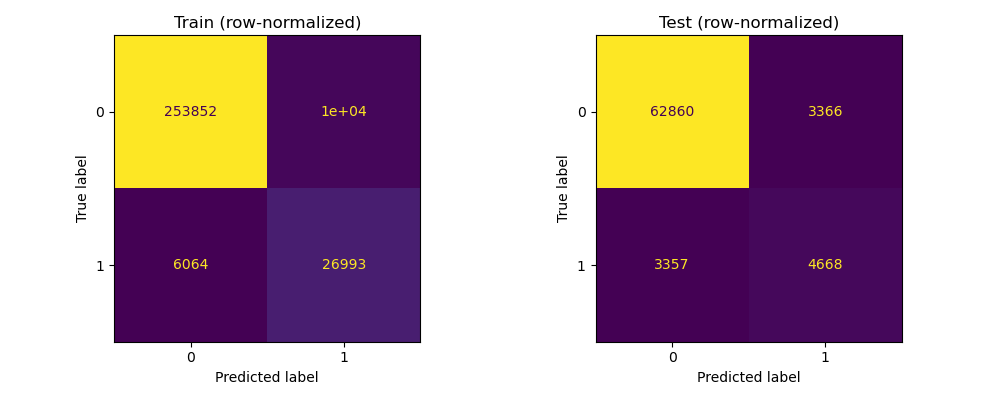

In [136]:
%matplotlib widget
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

bins = np.linspace(0, 1, 41)
for cls, c, lbl in [(0, 'b', 'Correct call (0)'), (1, 'r', 'Wrong call (1)')]:
    ax[0, 0].hist(xgb_test_probs[test_response.values == cls], bins=bins, color=c, alpha=.5, density=True, label=lbl)
ax[0, 0].axvline(thr, color='black', linestyle=':', linewidth=1.5, label=f'Threshold {thr:.2f}')
ax[0, 0].set(xlabel='Predicted P(wrong call)', ylabel='Density', title='Test: predicted probability by actual class')
ax[0, 0].legend()

for yt, pp, st, lbl in [(train_response, xgb_train_probs, 'g--', 'Train'), (test_response, xgb_test_probs, 'r-', 'Test')]:
    f, t, _ = roc_curve(yt, pp)
    ax[0, 1].plot(f, t, st, linewidth=2, label=f'{lbl} (AUC {roc_auc_score(yt, pp):.3f})')
ax[0, 1].plot([0, 1], [0, 1], 'k:', linewidth=1)
ax[0, 1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC'); ax[0, 1].legend()

for yt, pp, st, lbl in [(train_response, xgb_train_probs, 'g--', 'Train'), (test_response, xgb_test_probs, 'r-', 'Test')]:
    p_, r_, _ = precision_recall_curve(yt, pp)
    ax[1, 0].plot(r_, p_, st, linewidth=2, label=f'{lbl} (AP {average_precision_score(yt, pp):.3f})')
ax[1, 0].axhline(test_response.mean(), color='black', linestyle=':', linewidth=1.5, label='Base rate')
ax[1, 0].set(xlabel='Recall', ylabel='Precision', title='Precision-recall'); ax[1, 0].legend()

fp, mp = calibration_curve(test_response, xgb_test_probs, n_bins=10, strategy='quantile')
ax[1, 1].plot(mp, fp, 'ro-', linewidth=2, label='XGB (test)')
ax[1, 1].plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Perfect')
ax[1, 1].set(xlabel='Mean predicted probability', ylabel='Observed fraction wrong', title='Calibration (test)')
ax[1, 1].legend()

for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figs/XGB_WrongCall_Diagnostics.png", dpi=300)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, yt, pred, ttl in [(ax[0], train_response, xgb_train_preds, 'Train'), (ax[1], test_response, xgb_test_preds, 'Test')]:
    ConfusionMatrixDisplay.from_predictions(yt, pred, ax=a, colorbar=False, 
    # normalize='true', 
    # values_format='.2f'
    )
    a.set_title(f'{ttl} (row-normalized)')
plt.tight_layout()
plt.savefig("../figs/XGB_WrongCall_Confusion.png", dpi=300)
plt.show()

In [137]:
OUT_DIR = "../results/raw"
os.makedirs(OUT_DIR, exist_ok=True)

# `results` was already built after the model fit cell; reuse it.
preds_df = results.copy()

preds_path = os.path.join(OUT_DIR, "xgb_baseline_predictions_vs_actuals.csv")
preds_df.to_csv(preds_path, index=False)
print(f"Saved {len(preds_df):,} rows -> {preds_path}")
print(preds_df.head())

Saved 371,254 rows -> ../results/raw\xgb_baseline_predictions_vs_actuals.csv
   actual  pred_prob  pred_label  split
0       0   0.428053           0  train
1       0   0.000027           0  train
2       0   0.000183           0  train
3       0   0.000007           0  train
4       0   0.000011           0  train


In [138]:
OUT_DIR = "../results/stats"
os.makedirs(OUT_DIR, exist_ok=True)
def _metric_row(y_true, prob, pred, threshold):
    return {
        "threshold":  threshold,
        "log_loss":   log_loss(y_true, prob),
        "roc_auc":    roc_auc_score(y_true, prob),
        "pr_auc":     average_precision_score(y_true, prob),
        "accuracy":   accuracy_score(y_true, pred),
        "precision":  precision_score(y_true, pred, zero_division=0),
        "recall":     recall_score(y_true, pred, zero_division=0),
        "f1":         f1_score(y_true, pred, zero_division=0),
        "base_rate":  float(np.mean(y_true)),
        "n_rows":     len(y_true),
    }

metrics_df = pd.DataFrame([
    {"split": "train", **_metric_row(train_response, xgb_train_probs, xgb_train_preds, thr)},
    {"split": "test",  **_metric_row(test_response,  xgb_test_probs,  xgb_test_preds,  thr)},
])

metrics_path = os.path.join(OUT_DIR, "xgb_baseline_metrics.csv")
metrics_df.to_csv(metrics_path, index=False)
print(f"Saved metrics -> {metrics_path}")
display(metrics_df)

Saved metrics -> ../results/stats\xgb_baseline_metrics.csv


,split,threshold,log_loss,roc_auc,pr_auc,accuracy,precision,recall,f1,base_rate,n_rows
0,train,0.868607,0.299747,0.982050,0.881670,0.945597,0.727829,0.816559,0.769645,0.111302,297003
1,test,0.868607,0.341790,0.936174,0.714313,0.909456,0.581031,0.581682,0.581356,0.108079,74251
